In [ ]:
import os, glob, zipfile

# ---------- 1. Get the zip file ----------
# If you already uploaded the zip using the folder icon on the left,
# this finds it. Otherwise it asks you to choose it now.
zips = glob.glob("/content/*.zip")
if not zips:
    from google.colab import files
    print("Choose your dataset .zip file")
    files.upload()
    zips = glob.glob("/content/*.zip")

ZIP_PATH = zips[0]
print("Using zip:", ZIP_PATH)

# ---------- 2. Unzip ----------
EXTRACT_TO = "/content/soil_data"
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(EXTRACT_TO)
print("Unzipped")

# ---------- 3. Find the folder that contains the class folders ----------
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

def count_images(folder):
    return sum(1 for f in os.listdir(folder)
               if f.lower().endswith(IMG_EXT) and not f.startswith("._"))

candidates = []
for root, dirs, _ in os.walk(EXTRACT_TO):
    dirs[:] = [d for d in dirs if d != "__MACOSX"]       # skip Mac junk
    class_dirs = [d for d in dirs if count_images(os.path.join(root, d)) > 0]
    if len(class_dirs) >= 2:
        total = sum(count_images(os.path.join(root, d)) for d in class_dirs)
        candidates.append((total, root, class_dirs))

if not candidates:
    raise Exception("No class folders with images were found. "
                    "Check how your zip is organised.")

print("\nFolders found:")
for total, root, class_dirs in sorted(candidates, reverse=True):
    print(f"  {root}\n     classes: {class_dirs}\n     images: {total}")

# If there is a Train folder, prefer it; otherwise use the biggest folder
train_like = [c for c in candidates if "train" in c[1].lower()]
pool = train_like if train_like else candidates
pool.sort(reverse=True)
DATA_FOLDER = pool[0][1]

print("\n>>> USING DATA_FOLDER =", DATA_FOLDER)

Using zip: /content/archive.zip
Unzipped

Folders found:
  /content/soil_data/Soil types
     classes: ['Black Soil', 'Yellow Soil', 'Peat Soil', 'Cinder Soil', 'Laterite Soil']
     images: 156

>>> USING DATA_FOLDER = /content/soil_data/Soil types


Found 156 files belonging to 5 classes.
Classes: ['Black Soil', 'Cinder Soil', 'Laterite Soil', 'Peat Soil', 'Yellow Soil']


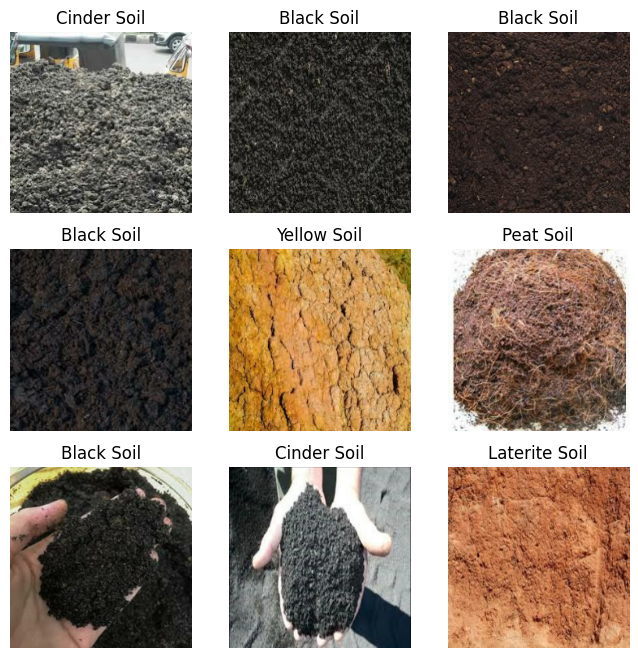

In [ ]:
import matplotlib.pyplot as plt
from tensorflow import keras

preview = keras.utils.image_dataset_from_directory(
    DATA_FOLDER, image_size=(224, 224), batch_size=9, shuffle=True)
names = preview.class_names
print("Classes:", names)

plt.figure(figsize=(8, 8))
for images, labels in preview.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(names[labels[i]])
        plt.axis("off")
plt.show()

Found 156 files belonging to 5 classes.
Using 125 files for training.
Found 156 files belonging to 5 classes.
Using 31 files for validation.
Classes: ['Black Soil', 'Cinder Soil', 'Laterite Soil', 'Peat Soil', 'Yellow Soil']
Epoch 1/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.1920 - loss: 2.3087 - val_accuracy: 0.1935 - val_loss: 1.7164
Epoch 2/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.2880 - loss: 1.7916 - val_accuracy: 0.3548 - val_loss: 1.4370
Epoch 3/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.3200 - loss: 1.5622 - val_accuracy: 0.4516 - val_loss: 1.2686
Epoch 4/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.4720 - loss: 1.3101 - val_accuracy: 0.7742 - val_loss: 1.0151
Epoch 5/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.5280 - loss: 1.2458 - val_accuracy: 0.8065 - val_loss: 0.8482
Epoch 6/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.6000 - loss: 1.1297 - val_accuracy: 0.8065 - val_loss: 0.7927
Epoch 7/15
4/4 ━━━━━━━━━━━━━━━━━━

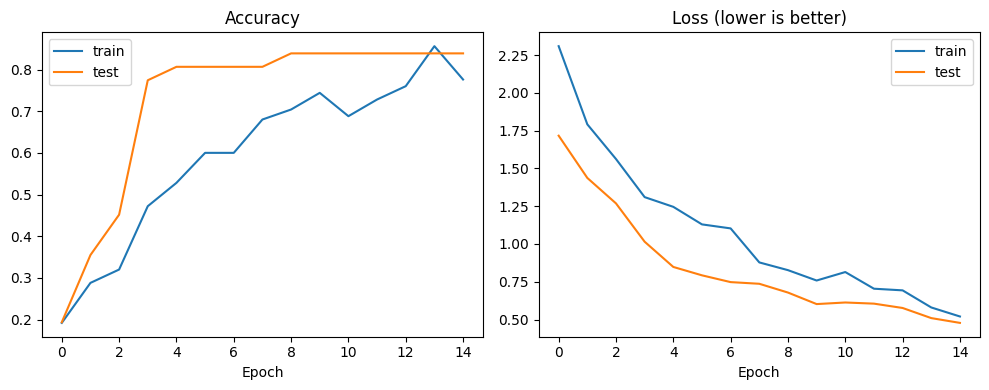

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

CLASSIFICATION REPORT


ValueError: Number of classes, 4, does not match size of target_names, 5. Try specifying the labels parameter

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

# ---------- Settings ----------
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 15

# ---------- 1. Load data: 80% train, 20% test ----------
train_data = keras.utils.image_dataset_from_directory(
    DATA_FOLDER, validation_split=0.2, subset="training",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH_SIZE)

test_data = keras.utils.image_dataset_from_directory(
    DATA_FOLDER, validation_split=0.2, subset="validation",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_data.class_names
print("Classes:", class_names)

train_data = train_data.prefetch(tf.data.AUTOTUNE)
test_data = test_data.prefetch(tf.data.AUTOTUNE)

# ---------- 2. Augmentation (random changes while training) ----------
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

# ---------- 3. Model: pretrained MobileNetV2 + new final layer ----------
base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base_model.trainable = False       # keep what it already knows

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# ---------- 4. Train (stops early if it stops improving) ----------
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(train_data, validation_data=test_data,
                    epochs=EPOCHS, callbacks=[early_stop])

# ---------- 5. Graphs ----------
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="test")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="test")
plt.title("Loss (lower is better)"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout()
plt.savefig("learning_curves.png")
plt.show()

# ---------- 6. Detailed results ----------
y_true = np.concatenate([lbl.numpy() for _, lbl in test_data])
y_pred = np.argmax(model.predict(test_data), axis=1)

print("\nCLASSIFICATION REPORT")
print(classification_report(y_true, y_pred, target_names=class_names))

print("CONFUSION MATRIX (rows = real class, columns = predicted class)")
print(confusion_matrix(y_true, y_pred))

# ---------- 7. Save the model ----------
model.save("soil_model.keras")
print("\nModel saved as soil_model.keras")

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

all_labels = list(range(len(class_names)))

y_true = np.concatenate([lbl.numpy() for _, lbl in test_data])
y_pred = np.argmax(model.predict(test_data), axis=1)

print("CLASSIFICATION REPORT")
print(classification_report(
    y_true, y_pred,
    labels=all_labels,
    target_names=class_names,
    zero_division=0))

print("CONFUSION MATRIX (rows = real class, columns = predicted class)")
print(confusion_matrix(y_true, y_pred, labels=all_labels))

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
CLASSIFICATION REPORT
               precision    recall  f1-score   support

   Black Soil       0.00      0.00      0.00         0
  Cinder Soil       0.00      0.00      0.00         0
Laterite Soil       0.00      0.00      0.00         0
    Peat Soil       0.00      0.00      0.00         2
  Yellow Soil       1.00      0.90      0.95        29

     accuracy                           0.84        31
    macro avg       0.20      0.18      0.19        31
 weighted avg       0.94      0.84      0.88        31

CONFUSION MATRIX (rows = real class, columns = predicted class)
[[ 0  0  0  0  0]
 [ 0  0  0  0  0]
 [ 0  0  0  0  0]
 [ 0  1  1  0  0]
 [ 0  0  3  0 26]]


Choose a soil photo


Saving sample soil.jpeg to sample soil.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


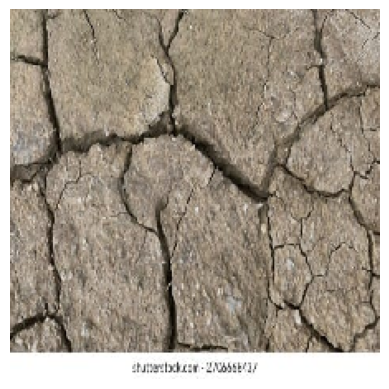

Cinder Soil: 30.1%
Yellow Soil: 29.5%
Peat Soil: 25.5%
Laterite Soil: 11.6%
Black Soil: 3.3%


In [ ]:
from google.colab import files

print("Choose a soil photo")
uploaded = files.upload()
path = list(uploaded.keys())[0]

img = keras.utils.load_img(path, target_size=IMG_SIZE)
arr = np.expand_dims(keras.utils.img_to_array(img), axis=0)
probs = model.predict(arr)[0]

plt.imshow(img); plt.axis("off"); plt.show()
for name, p in sorted(zip(class_names, probs), key=lambda t: -t[1]):
    print(f"{name}: {p*100:.1f}%")